<a href="https://colab.research.google.com/github/onumaechimargaret-wq/My-Project-work-gas-adsorption-modelling-python/blob/Final-Project/final_Separation_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ISOTHERM FITTING RESULTS (T = 303 K)

Romulus - N2  (15 points)
  Model                      R2      RMSE      AICc   Parameters (b in 1/Pa) +/- 95% CI
  Langmuir              0.99972    0.0122   -127.31   qs=2.542±0.052, b=4.35e-06±2.2e-07
  Sips                  0.99994    0.0055   -147.73   qs=2.771±0.083, b=3.564e-06±2.6e-07, n=0.914±0.024
  Dual-site Langmuir    0.99996    0.0048   -148.09   qs1=2.44±0.16, b1=3.258e-06±5.6e-07, qs2=0.2508±0.22, b2=2.463e-05±1.9e-05

Romulus - O2  (7 points)
  Model                      R2      RMSE      AICc   Parameters (b in 1/Pa) +/- 95% CI
  Langmuir              0.99960    0.0063    -63.98   qs=4.705±1.5, b=3.414e-07±1.3e-07
  Sips                  0.99960    0.0063    -56.98   qs=4.7±6.3, b=3.419e-07±6.5e-07, n=1±0.19
  Dual-site Langmuir    0.99961    0.0062    -43.18   qs1=0.00215±0.038, b1=0.01±18, qs2=4.843±2.9, b2=3.287e-07±2.5e-07

Remus - N2  (11 points)
  Model                      R2      RMSE      AICc   Parameters (b in 1/Pa) +/- 

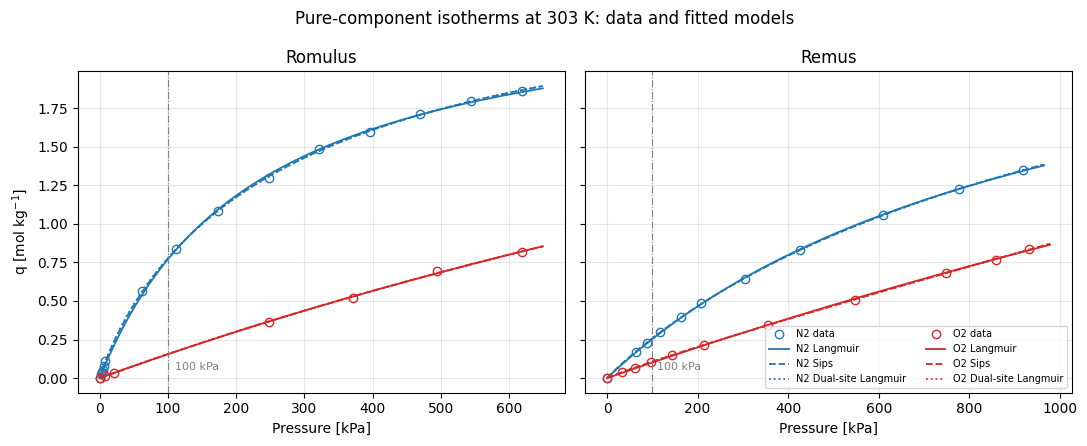

In [25]:
"""
Mission O2 - Static measurements
CHEN40461/60461 Chemical Separations for a Cleaner World

What this script does
1. Loads the pure-component isotherm data (Table 1) for N2 and O2 on Romulus and Remus at 303 K.
2. Fits three candidate isotherm models by non-linear least squares:
     - Single-site Langmuir (SSL)      q = qs*b*P / (1 + b*P)
     - Sips (Langmuir-Freundlich)      q = qs*(b*P)^n / (1 + (b*P)^n)
     - Dual-site Langmuir (DSL)        q = qs1*b1*P/(1+b1*P) + qs2*b2*P/(1+b2*P)
3. Compares the models with R^2, RMSE and AIC (AIC penalises extra parameters).
4. Compares the adsorbents: capacity at 100 kPa, Henry constants, and N2/O2 selectivity.
5. Plots data vs fits and saves the chosen parameters to isotherm_params.json
   so the breakthrough (dynamic) model can load them directly.

Units: P in Pa, q in mol/kg, b in 1/Pa.
"""

import json
import numpy as np
from scipy.optimize import least_squares
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------------
# 1. Experimental data (Table 1, 303 K)
# ----------------------------------------------------------------------------
DATA = {
    "Romulus": {
        "N2": {
            "P": [0.0, 2026.5, 3039.75, 4053.0, 6079.5, 8106.0, 61909.575, 111356.175,
                  173265.75, 247435.65, 321706.875, 395978.1, 470148.0, 544419.225, 618690.45],
            "q": [0.0, 0.025, 0.038, 0.053, 0.079, 0.108, 0.562, 0.835,
                  1.082, 1.295, 1.482, 1.597, 1.714, 1.795, 1.861],
        },
        "O2": {
            "P": [0.0, 8106.0, 20265.0, 247435.65, 371153.475, 494871.3, 618690.45],
            "q": [0.0, 0.015, 0.035, 0.366, 0.521, 0.693, 0.815],
        },
    },
    "Remus": {
        "N2": {
            "P": [0, 63400, 88700, 117500, 162500, 208500, 303800, 427000, 609500, 776600, 919000],
            "q": [0.0, 0.1674, 0.2300, 0.2994, 0.3934, 0.4848, 0.6450, 0.8280, 1.0588, 1.2249, 1.3472],
        },
        "O2": {
            "P": [0, 33200, 61300, 96100, 143200, 214800, 355900, 548200, 747900, 859000, 931700],
            "q": [0.0, 0.0372, 0.0679, 0.1022, 0.1504, 0.2138, 0.3455, 0.5089, 0.6830, 0.7679, 0.8348],
        },
    },
}

T = 303.0          # K
P_FEED = 100e3     # Pa, process pressure (Table 2)


# ----------------------------------------------------------------------------
# 2. Isotherm models
#    Parameters are fitted in a scaled form (b in 1/kPa) so the optimiser sees
#    numbers of similar magnitude; they are converted back to 1/Pa afterwards.
# ----------------------------------------------------------------------------
def langmuir(P, qs, b):
    return qs * b * P / (1.0 + b * P)


def sips(P, qs, b, n):
    x = (b * P) ** n
    return qs * x / (1.0 + x)


def dual_langmuir(P, qs1, b1, qs2, b2):
    return langmuir(P, qs1, b1) + langmuir(P, qs2, b2)


MODELS = {
    "Langmuir": {
        "f": langmuir,
        "names": ["qs", "b"],
        "p0": [2.0, 1e-3],                 # b in 1/kPa during fitting
        "lb": [1e-6, 1e-8],
        "ub": [100.0, 10.0],
        "b_index": [1],                    # which parameters are affinities
    },
    "Sips": {
        "f": sips,
        "names": ["qs", "b", "n"],
        "p0": [2.0, 1e-3, 1.0],
        "lb": [1e-6, 1e-8, 0.2],
        "ub": [100.0, 10.0, 3.0],
        "b_index": [1],
    },
    "Dual-site Langmuir": {
        "f": dual_langmuir,
        "names": ["qs1", "b1", "qs2", "b2"],
        "p0": [1.0, 1e-2, 1.0, 1e-3],
        "lb": [1e-6, 1e-8, 1e-6, 1e-8],
        "ub": [100.0, 10.0, 100.0, 10.0],
        "b_index": [1, 3],
    },
}


def fit_model(model_name, P_pa, q):
    """Fit one model to one data set. Returns parameters (b in 1/Pa) and statistics."""
    m = MODELS[model_name]
    P_kpa = P_pa / 1e3

    def residuals(p):
        return m["f"](P_kpa, *p) - q

    # Try a few starting points and keep the best: non-linear fits can get stuck
    best = None
    rng = np.random.default_rng(0)
    starts = [np.array(m["p0"])]
    for _ in range(20):
        starts.append(np.array(m["p0"]) * 10 ** rng.uniform(-1, 1, len(m["p0"])))

    for x0 in starts:
        x0 = np.clip(x0, np.array(m["lb"]) * 1.0001, np.array(m["ub"]) * 0.9999)
        res = least_squares(residuals, x0, bounds=(m["lb"], m["ub"]),
                            method="trf", x_scale="jac", max_nfev=20000)
        if best is None or res.cost < best.cost:
            best = res

    p = best.x.copy()
    resid = best.fun
    n_pts = len(q)
    k = len(p)
    sse = float(np.sum(resid ** 2))
    sst = float(np.sum((q - q.mean()) ** 2))
    r2 = 1.0 - sse / sst
    rmse = np.sqrt(sse / n_pts)
    # Corrected AIC for small samples (lower = better)
    aic = n_pts * np.log(sse / n_pts) + 2 * k
    aicc = aic + (2 * k * (k + 1)) / (n_pts - k - 1) if n_pts - k - 1 > 0 else np.inf

    # Approximate 95 % confidence intervals from the Jacobian
    try:
        J = best.jac
        cov = np.linalg.inv(J.T @ J) * sse / max(n_pts - k, 1)
        ci95 = 1.96 * np.sqrt(np.diag(cov))
    except np.linalg.LinAlgError:
        ci95 = np.full(k, np.nan)

    # Convert affinity constants back from 1/kPa to 1/Pa
    for i in m["b_index"]:
        p[i] /= 1e3
        ci95[i] /= 1e3

    return {
        "params": dict(zip(m["names"], p.tolist())),
        "ci95": dict(zip(m["names"], ci95.tolist())),
        "R2": r2, "RMSE": rmse, "AICc": aicc, "SSE": sse,
    }


def evaluate(model_name, params, P_pa):
    """Evaluate a fitted model at pressure(s) in Pa."""
    m = MODELS[model_name]
    return m["f"](np.asarray(P_pa, dtype=float), *[params[n] for n in m["names"]])


def henry_constant(model_name, params):
    """Initial slope dq/dP at P -> 0, in mol/(kg Pa)."""
    if model_name == "Langmuir":
        return params["qs"] * params["b"]
    if model_name == "Dual-site Langmuir":
        return params["qs1"] * params["b1"] + params["qs2"] * params["b2"]
    if model_name == "Sips":
        # Finite only for n = 1; for n != 1 report a numerical slope at low P
        P_low = 100.0
        return float(evaluate(model_name, params, P_low)) / P_low
    raise ValueError(model_name)


# ----------------------------------------------------------------------------
# 3. Fit everything
# ----------------------------------------------------------------------------
results = {}
for ads, gases in DATA.items():
    results[ads] = {}
    for gas, d in gases.items():
        P = np.array(d["P"], dtype=float)
        q = np.array(d["q"], dtype=float)
        results[ads][gas] = {name: fit_model(name, P, q) for name in MODELS}

print("=" * 88)
print("ISOTHERM FITTING RESULTS (T = 303 K)")
print("=" * 88)
for ads in results:
    for gas in results[ads]:
        print(f"\n{ads} - {gas}  ({len(DATA[ads][gas]['q'])} points)")
        print(f"  {'Model':<20}{'R2':>9}{'RMSE':>10}{'AICc':>10}   Parameters (b in 1/Pa) +/- 95% CI")
        for name, r in results[ads][gas].items():
            pstr = ", ".join(f"{k}={v:.4g}±{r['ci95'][k]:.2g}" for k, v in r["params"].items())
            print(f"  {name:<20}{r['R2']:>9.5f}{r['RMSE']:>10.4f}{r['AICc']:>10.2f}   {pstr}")

# ----------------------------------------------------------------------------
# 4. Model selection
#    The breakthrough model needs a multicomponent isotherm. The single-site
#    Langmuir extends naturally to the extended (competitive) Langmuir model,
#    which is thermodynamically consistent when qs is shared. We therefore
#    choose the simplest model that fits adequately, and report AICc so the
#    choice is justified rather than assumed.
# ----------------------------------------------------------------------------
CHOSEN = "Langmuir"

print("\n" + "=" * 88)
print(f"ADSORBENT COMPARISON using the {CHOSEN} fits")
print("=" * 88)
summary = {}
for ads in results:
    pN2 = results[ads]["N2"][CHOSEN]["params"]
    pO2 = results[ads]["O2"][CHOSEN]["params"]
    KN2 = henry_constant(CHOSEN, pN2)
    KO2 = henry_constant(CHOSEN, pO2)
    qN2_feed = float(evaluate(CHOSEN, pN2, P_FEED))
    qO2_feed = float(evaluate(CHOSEN, pO2, P_FEED))

    # (a) Henry's-law (low-pressure) selectivity
    S_henry = KN2 / KO2
    # (b) Ratio of pure-component capacities at 100 kPa
    S_pure = qN2_feed / qO2_feed
    # (c) Extended-Langmuir selectivity for an equimolar mixture at 100 kPa
    #     S = (qN2/qO2)/(yN2/yO2) = (qsN2*bN2)/(qsO2*bO2) for extended Langmuir
    #     -> identical to Henry selectivity, independent of composition.
    summary[ads] = {
        "K_N2 [mol/kg/Pa]": KN2, "K_O2 [mol/kg/Pa]": KO2,
        "q_N2 at 100 kPa [mol/kg]": qN2_feed, "q_O2 at 100 kPa [mol/kg]": qO2_feed,
        "Henry selectivity N2/O2": S_henry,
        "Pure-component capacity ratio at 100 kPa": S_pure,
    }
    print(f"\n{ads}")
    for k, v in summary[ads].items():
        print(f"  {k:<45}{v:.4g}")

# ----------------------------------------------------------------------------
# 5. Figure: data and fits
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
colours = {"N2": "tab:blue", "O2": "tab:red"}
styles = {"Langmuir": "-", "Sips": "--", "Dual-site Langmuir": ":"}

for ax, ads in zip(axes, DATA):
    for gas, d in DATA[ads].items():
        P = np.array(d["P"]) / 1e3
        ax.plot(P, d["q"], "o", color=colours[gas], mfc="none", label=f"{gas} data")
        P_fine = np.linspace(0, max(d["P"]) * 1.05, 300)
        for name, ls in styles.items():
            q_fit = evaluate(name, results[ads][gas][name]["params"], P_fine)
            ax.plot(P_fine / 1e3, q_fit, ls, color=colours[gas], lw=1.3,
                    label=f"{gas} {name}")
    ax.axvline(P_FEED / 1e3, color="grey", lw=0.8, ls="-.")
    ax.text(P_FEED / 1e3 + 10, 0.05, "100 kPa", color="grey", fontsize=8)
    ax.set_title(ads)
    ax.set_xlabel("Pressure [kPa]")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("q [mol kg$^{-1}$]")
axes[1].legend(fontsize=7, ncol=2, loc="lower right")
fig.suptitle("Pure-component isotherms at 303 K: data and fitted models")
fig.tight_layout()
fig.savefig("isotherm_fits.png", dpi=200)
print("\nFigure saved to isotherm_fits.png")

# ----------------------------------------------------------------------------
# 6. Save parameters for the dynamic (breakthrough) model
# ----------------------------------------------------------------------------
out = {
    "temperature_K": T,
    "chosen_model": CHOSEN,
    "units": {"qs": "mol/kg", "b": "1/Pa"},
    "fits": results,
    "comparison": summary,
}
with open("isotherm_params.json", "w") as fh:
    json.dump(out, fh, indent=2)
print("Parameters saved to isotherm_params.json")

Axial dispersion coefficient:
DL = 5.723100e-05 m2/s

LDF rate constant:
Dp = 2.493667e-05 m2/s
k = 374.0500 1/s

Adsorption factor:
alpha = 52.9964 kg/mol

Spatial discretisation:
Number of grid points = 51
Grid spacing = 0.006400 m

Running simulation for Romulus...
Romulus simulation completed successfully.

Running simulation for Remus...
Remus simulation completed successfully.

Romulus gas-phase mole fraction check:
Maximum deviation from 1 = 0.9995558043919937

Remus gas-phase mole fraction check:
Maximum deviation from 1 = 0.9028676556495874


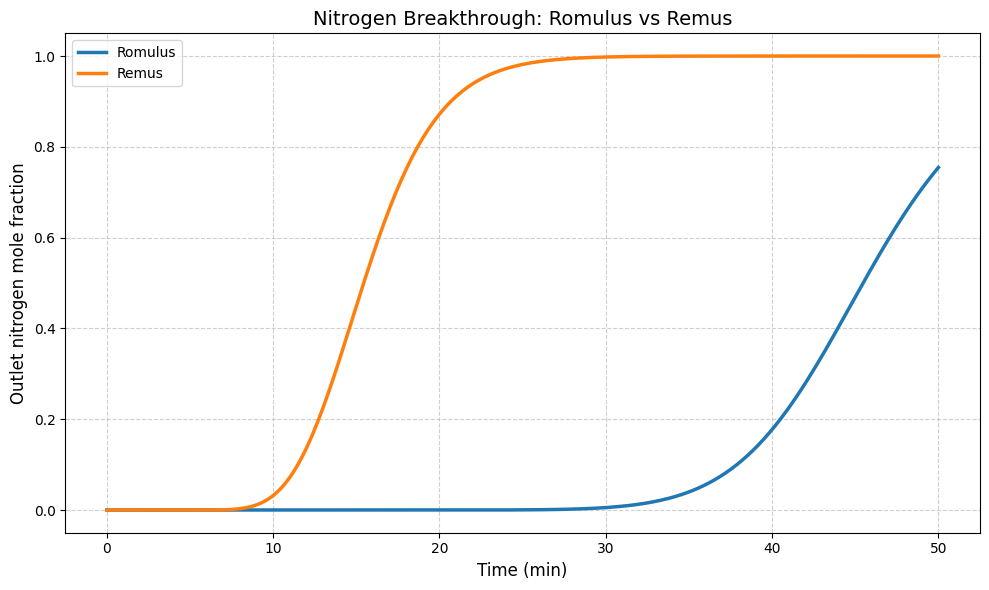

In [26]:

# ============================================================
# BREAKTHROUGH MODEL USING THE METHOD OF LINES
# Comparison of Romulus and Remus
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# STEP 1: LANGMUIR PARAMETERS
# ============================================================

adsorbents = {
    "Romulus": {
        "N2": {"qm": 2.5419, "b": 4.35e-6},
        "O2": {"qm": 4.7049, "b": 3.41e-7}
    },

    "Remus": {
        "N2": {"qm": 2.8344, "b": 9.80e-7},
        "O2": {"qm": 6.0977, "b": 1.69e-7}
    }
}

# ============================================================
# STEP 2: COLUMN AND OPERATING CONDITIONS
# ============================================================

L = 0.32
void = 0.32
eps_s = 990
rp = 0.001
tortuosity = 3

Dm = 7.481e-5
R = 8.314
T = 303
P = 100000
v_in = 4.864e-3

# ============================================================
# STEP 3: CALCULATE DISPERSION COEFFICIENT
# ============================================================

DL = 0.7 * Dm + v_in * rp

print("Axial dispersion coefficient:")
print(f"DL = {DL:.6e} m2/s")

# ============================================================
# STEP 4: CALCULATE LDF RATE CONSTANT
# ============================================================

# Modelling assumption:
# Particle diffusivity = molecular diffusivity / tortuosity

Dp = Dm / tortuosity

k = 15 * Dp / rp**2

print("\nLDF rate constant:")
print(f"Dp = {Dp:.6e} m2/s")
print(f"k = {k:.4f} 1/s")

# ============================================================
# STEP 5: GAS-SOLID ADSORPTION FACTOR
# ============================================================

alpha = (R * T * eps_s * (1 - void)) / (P * void)

print("\nAdsorption factor:")
print(f"alpha = {alpha:.4f} kg/mol")

# ============================================================
# STEP 6: SPATIAL DISCRETISATION
# ============================================================

N = 51

z = np.linspace(0, L, N)

dz = z[1] - z[0]

print("\nSpatial discretisation:")
print(f"Number of grid points = {N}")
print(f"Grid spacing = {dz:.6f} m")

# ============================================================
# STEP 7: COMPETITIVE LANGMUIR EQUILIBRIUM
# ============================================================

def equilibrium_loading(name, yN2, yO2):

    N2 = adsorbents[name]["N2"]
    O2 = adsorbents[name]["O2"]

    PN2 = yN2 * P
    PO2 = yO2 * P

    denominator = (
        1
        + N2["b"] * PN2
        + O2["b"] * PO2
    )

    qN2 = (
        N2["qm"] * N2["b"] * PN2
        / denominator
    )

    qO2 = (
        O2["qm"] * O2["b"] * PO2
        / denominator
    )

    return qN2, qO2

# ============================================================
# STEP 8: METHOD OF LINES
# ============================================================

def breakthrough_model(t, state, name):

    # Divide the state vector into four variables

    yN2 = state[0:N]
    yO2 = state[N:2*N]

    qN2 = state[2*N:3*N]
    qO2 = state[3*N:4*N]

    # Limit mole fractions for equilibrium calculation
    yN2_eq = np.clip(yN2, 0, 1)
    yO2_eq = np.clip(yO2, 0, 1)

    # Calculate equilibrium loadings
    qN2_star, qO2_star = equilibrium_loading(
        name, yN2_eq, yO2_eq
    )

    # LDF solid-phase equations
    dqN2_dt = k * (qN2_star - qN2)
    dqO2_dt = k * (qO2_star - qO2)

    # Gas-phase derivatives
    def gas_balance(y, dq_dt, feed):

        # Danckwerts inlet boundary:
        # y(0) = feed + (DL/v) * dy/dz

        ghost_left = (
            y[1]
            - 2 * dz * v_in / DL * (y[0] - feed)
        )

        # Zero-gradient outlet boundary
        ghost_right = y[-2]

        # Add ghost points
        y_extended = np.concatenate((
            [ghost_left],
            y,
            [ghost_right]
        ))

        # First spatial derivative
        dy_dz = (
            y_extended[2:] - y_extended[:-2]
        ) / (2 * dz)

        # Second spatial derivative
        d2y_dz2 = (
            y_extended[2:]
            - 2 * y_extended[1:-1]
            + y_extended[:-2]
        ) / dz**2

        # Gas-phase component balance
        dydt = (
            DL * d2y_dz2
            - v_in * dy_dz
            - alpha * dq_dt
        )

        return dydt

    # Pure nitrogen feed
    dyN2_dt = gas_balance(
        yN2, dqN2_dt, 1.0
    )

    # No oxygen in the feed
    dyO2_dt = gas_balance(
        yO2, dqO2_dt, 0.0
    )

    # Return all four sets of ODEs
    return np.concatenate((
        dyN2_dt,
        dyO2_dt,
        dqN2_dt,
        dqO2_dt
    ))

# ============================================================
# STEP 9: INITIAL CONDITIONS
# ============================================================

def run_simulation(name):

    # Initially pure oxygen in the gas phase
    yN2_initial = np.zeros(N)
    yO2_initial = np.ones(N)

    # Initially no nitrogen on the adsorbent
    qN2_initial = np.zeros(N)

    # Initially oxygen-saturated adsorbent
    qN2_0, qO2_0 = equilibrium_loading(
        name,
        0.0,
        1.0
    )

    qO2_initial = np.full(N, qO2_0)

    # Combine all initial conditions
    initial_state = np.concatenate((
        yN2_initial,
        yO2_initial,
        qN2_initial,
        qO2_initial
    ))

    # Simulation time
    t_end = 3000

    time_points = np.linspace(0, t_end, 301)

    # Solve the ODE system
    solution = solve_ivp(
        fun=lambda t, state: breakthrough_model(
            t, state, name
        ),
        t_span=(0, t_end),
        y0=initial_state,
        t_eval=time_points,
        method="BDF",
        rtol=1e-6,
        atol=1e-8
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    # Extract outlet nitrogen concentration
    outlet_N2 = solution.y[N-1, :]

    # Extract outlet oxygen concentration
    outlet_O2 = solution.y[2*N-1, :]

    return solution, outlet_N2, outlet_O2

# ============================================================
# STEP 10: RUN BOTH ADSORBENTS
# ============================================================

results = {}

for name in adsorbents:

    print(f"\nRunning simulation for {name}...")

    solution, outlet_N2, outlet_O2 = run_simulation(name)

    results[name] = {
        "time": solution.t,
        "N2": outlet_N2,
        "O2": outlet_O2,
        "solution": solution
    }

    print(f"{name} simulation completed successfully.")

# ============================================================
# STEP 11: CHECK MOLE FRACTION SUM
# ============================================================

for name in adsorbents:

    solution = results[name]["solution"]

    yN2 = solution.y[0:N, :]
    yO2 = solution.y[N:2*N, :]

    mole_fraction_sum = yN2 + yO2

    print(f"\n{name} gas-phase mole fraction check:")
    print(
        "Maximum deviation from 1 =",
        np.max(np.abs(mole_fraction_sum - 1))
    )

# ============================================================
# STEP 12: PLOT BREAKTHROUGH CURVES
# ============================================================

plt.figure(figsize=(10, 6))

for name in adsorbents:

    time_minutes = results[name]["time"] / 60

    nitrogen = results[name]["N2"]

    plt.plot(
        time_minutes,
        nitrogen,
        linewidth=2.5,
        label=name
    )

plt.xlabel("Time (min)", fontsize=12)

plt.ylabel(
    "Outlet nitrogen mole fraction",
    fontsize=12
)

plt.title(
    "Nitrogen Breakthrough: Romulus vs Remus",
    fontsize=14
)

plt.ylim(-0.05, 1.05)

plt.grid(True, linestyle="--", alpha=0.6)

plt.legend()

plt.tight_layout()

plt.show()


BASE CASE BREAKTHROUGH SIMULATIONS

Romulus
  LDF constants k_N2 = 6.229 1/s, k_O2 = 30.900 1/s;  D_L = 5.723e-05 m2/s
  Breakthrough time (y_N2 = 0.05)   :   2468.1 s
  Stoichiometric time (simulation)     :   2752.3 s
  Shock time (equilibrium theory)      :   2752.3 s
  Deviation sim vs eq. theory          :    0.000 %
  Outlet velocity before breakthrough  : sim 1.057e-03, eq. theory 1.073e-03 m/s
  Bed utilisation at breakthrough      :     89.7 %   (LUB = 3.3 cm)

Remus
  LDF constants k_N2 = 18.969 1/s, k_O2 = 47.429 1/s;  D_L = 5.723e-05 m2/s
  Breakthrough time (y_N2 = 0.05)   :    787.2 s
  Stoichiometric time (simulation)     :    947.9 s
  Shock time (equilibrium theory)      :    947.9 s
  Deviation sim vs eq. theory          :    0.000 %
  Outlet velocity before breakthrough  : sim 2.139e-03, eq. theory 2.148e-03 m/s
  Bed utilisation at breakthrough      :     83.0 %   (LUB = 5.4 cm)

Grid convergence (Romulus, breakthrough time):
  N =   30:  t_b = 2480.4 s
  N =   60: 

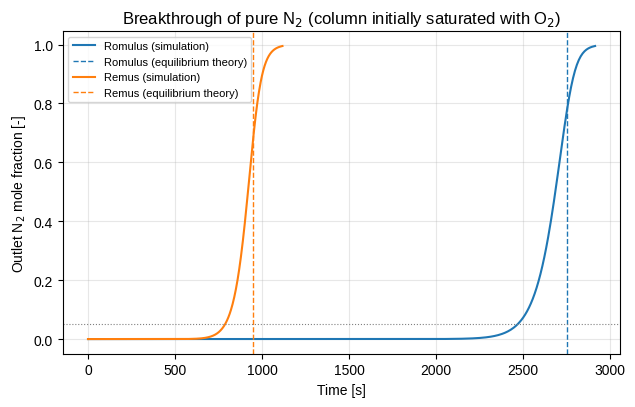

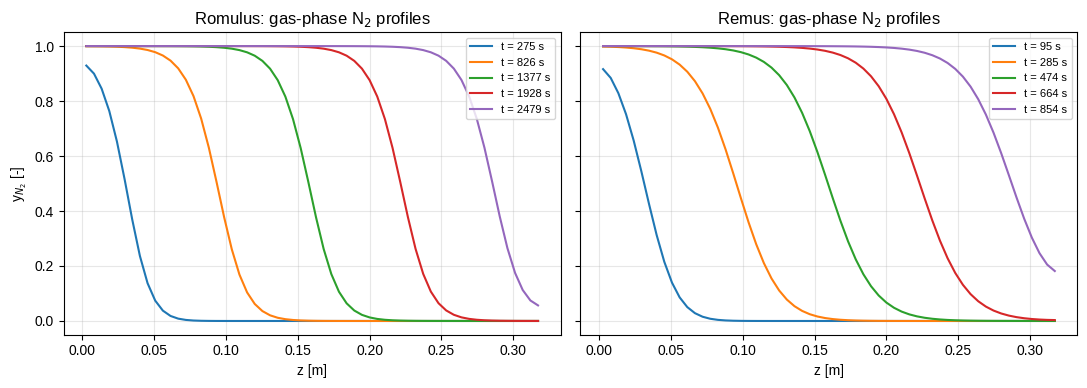

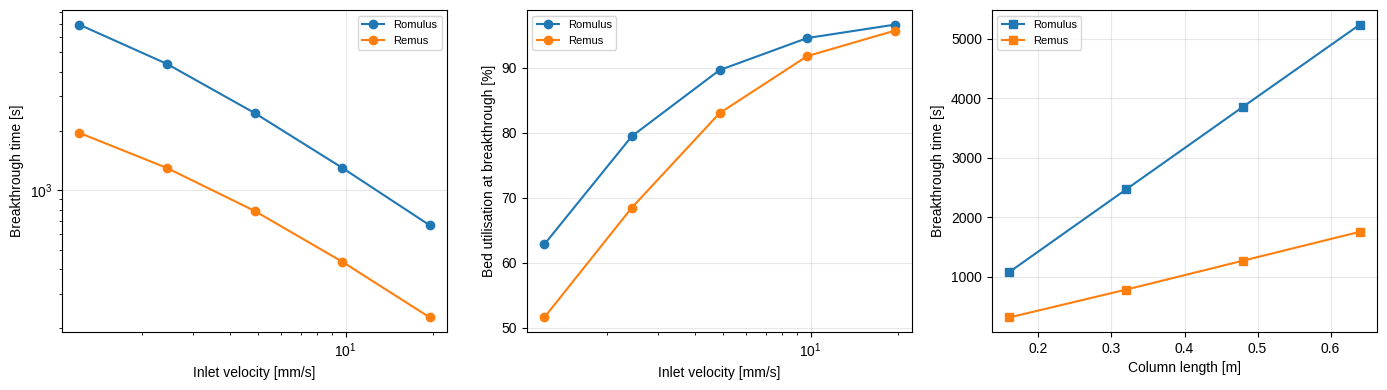

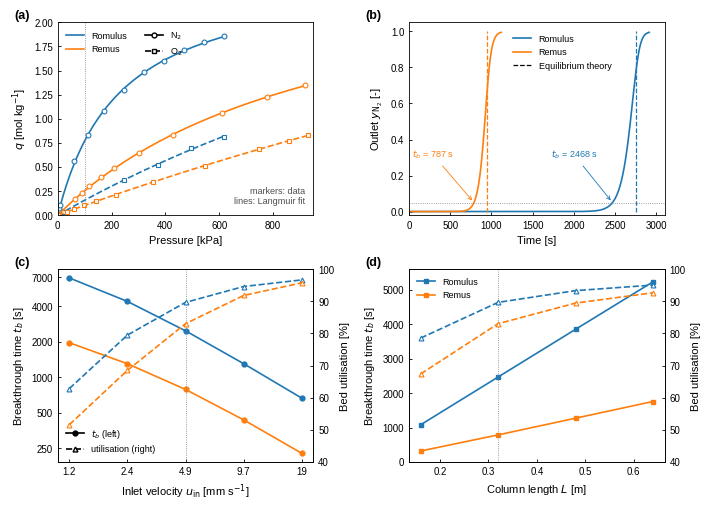

In [31]:
"""
Mission O2 - Dynamic measurements (breakthrough simulations)
CHEN40461/60461 Chemical Separations for a Cleaner World

Simulates breakthrough of pure N2 through a column initially saturated with pure O2
(both fluid and solid phases), for adsorbents Romulus and Remus.

Model (isothermal, isobaric, axially dispersed plug flow, LDF kinetics):
  Fluid, component i (Eq. 1):
      dy_i/dt = D_L d2y_i/dz2 - d(y_i v)/dz - (R T / P) * rho_s (1-eps)/eps * dq_i/dt
  Overall balance (sum of Eq. 1 over i, using sum(y_i) = 1):
      dv/dz = -(R T / P) * rho_s (1-eps)/eps * sum_i dq_i/dt
  Solid (Eq. 5), linear driving force:
      dq_i/dt = k_i (q_i* - q_i)
  Equilibrium: extended (competitive) Langmuir from the static fits
      q_i* = qs_i b_i P y_i / (1 + sum_j b_j P y_j)
  Axial dispersion (Eq. 2):  D_L = 0.7 D_m + v_in r_p
  Boundary conditions: Danckwerts at z = 0 (Eq. 3), zero gradient at z = L (Eq. 4)

Numerics:
  Finite volume method (method of lines) on N cells. Convective face values are
  reconstructed with a van Leer flux limiter (2nd order away from the front, no
  oscillations at the front). Dispersive fluxes use central differences.
  Danckwerts inlet is imposed in flux form: total N2 flux entering cell 1 = v_in*y_feed.
  The velocity at each face is obtained by integrating the overall balance from the inlet.
  The resulting stiff ODE system is integrated with scipy's BDF solver (variable order,
  variable step, implicit); the right-hand side is vectorised so the finite-difference
  Jacobian is evaluated in a single call.

Outputs:
  breakthrough_curves.png, column_profiles.png, sensitivity.png, dynamic_results.json
"""

import json
import os
import sys
import numpy as np
from scipy.integrate import solve_ivp, trapezoid
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------------
# 1. Parameters (Table 2)
# ----------------------------------------------------------------------------
BASE = {
    "L": 0.32,            # column length [m]
    "eps": 0.32,          # column (bed) void fraction [-]
    "eps_p": 0.32,        # particle porosity [-]  ASSUMPTION: not given, taken = bed voidage
    "rho_s": 990.0,       # particle density [kg/m3]
    "r_p": 1e-3,          # particle radius [m]
    "tau": 3.0,           # tortuosity [-]
    "D_m": 7.481e-5,      # molecular diffusivity [m2/s]
    "R": 8.314,           # [m3 Pa / mol / K]
    "T": 303.0,           # [K]
    "P": 100e3,           # [Pa]
    "v_in": 4.864e-3,     # inlet (interstitial) velocity [m/s]  ASSUMPTION: interstitial
    "y_feed": 1.0,        # pure N2 feed
    "N": 60,              # number of finite volumes
}
Y_BREAK = 0.05            # breakthrough defined as 5 % N2 at the outlet (product <95 % O2)

# ----------------------------------------------------------------------------
# 2. Isotherm parameters (from static_isotherms.py)
# ----------------------------------------------------------------------------
FALLBACK = {   # single-site Langmuir fits, b in 1/Pa, qs in mol/kg
    "Romulus": {"N2": {"qs": 2.542, "b": 4.350e-6}, "O2": {"qs": 4.705, "b": 3.414e-7}},
    "Remus":   {"N2": {"qs": 2.834, "b": 9.801e-7}, "O2": {"qs": 6.098, "b": 1.688e-7}},
}


def load_isotherms(path="isotherm_params.json"):
    if not os.path.exists(path):
        print("isotherm_params.json not found - using hard-coded Langmuir parameters")
        return FALLBACK
    with open(path) as fh:
        d = json.load(fh)
    iso = {}
    for ads in d["fits"]:
        iso[ads] = {g: d["fits"][ads][g]["Langmuir"]["params"] for g in ("N2", "O2")}
    return iso


ISO = load_isotherms()


def q_star(iso, y_N2, P):
    """Extended Langmuir equilibrium loadings [mol/kg] for a binary N2/O2 gas."""
    pN2, pO2 = P * y_N2, P * (1.0 - y_N2)
    denom = 1.0 + iso["N2"]["b"] * pN2 + iso["O2"]["b"] * pO2
    qN2 = iso["N2"]["qs"] * iso["N2"]["b"] * pN2 / denom
    qO2 = iso["O2"]["qs"] * iso["O2"]["b"] * pO2 / denom
    return qN2, qO2


def ldf_constants(iso, p):
    """
    Macropore-diffusion-controlled LDF constant (Glueckauf 15/rp^2 approximation, as used by
    Haghpanah et al., 2013):
        k_i = (c_i / q_i*) * 15 eps_p D_p / r_p^2,   D_p = D_m / tau
    with c_i and q_i* evaluated for the pure component at the column pressure
    (q_i* on a particle-volume basis, rho_s * q [mol/m3]).
    """
    c = p["P"] / (p["R"] * p["T"])
    Dp = p["D_m"] / p["tau"]
    k = {}
    for g, y in (("N2", 1.0), ("O2", 0.0)):
        qN2, qO2 = q_star(iso, y, p["P"])
        q_vol = p["rho_s"] * (qN2 if g == "N2" else qO2)
        k[g] = (c / q_vol) * 15.0 * p["eps_p"] * Dp / p["r_p"] ** 2
    return k


# ----------------------------------------------------------------------------
# 3. Finite-volume right-hand side
# ----------------------------------------------------------------------------
def make_rhs(iso, p):
    N = p["N"]
    dz = p["L"] / N
    DL = 0.7 * p["D_m"] + p["v_in"] * p["r_p"]
    alpha = p["R"] * p["T"] / p["P"] * p["rho_s"] * (1 - p["eps"]) / p["eps"]
    k = ldf_constants(iso, p)
    small = 1e-8

    def rhs(t, x):
        # Works for x of shape (3N,) or (3N, m): vectorised so the solver can build the
        # finite-difference Jacobian in a single call (much faster).
        vec = x.ndim == 2
        X = x if vec else x[:, None]
        y = X[:N]   # no clipping: keeps the RHS smooth for the implicit solver
        qN2 = X[N:2 * N]
        qO2 = X[2 * N:]
        m = X.shape[1]

        # Solid phase (LDF)
        qN2s, qO2s = q_star(iso, y, p["P"])
        dqN2 = k["N2"] * (qN2s - qN2)
        dqO2 = k["O2"] * (qO2s - qO2)

        # Face velocities from the overall balance (faces 0..N)
        v = np.empty((N + 1, m))
        v[0] = p["v_in"]
        v[1:] = p["v_in"] - dz * alpha * np.cumsum(dqN2 + dqO2, axis=0)

        # Convective face values (flow in +z): van Leer reconstruction
        dy_fwd = np.diff(y, axis=0)               # y[j+1]-y[j], shape (N-1, m)
        y_face = np.empty((N + 1, m))
        y_face[N] = y[-1]                         # outlet face: upwind cell
        y_face[1] = y[0]                          # first interior face: first-order upwind
        a = y[1:-1] - y[:-2]                      # upstream difference
        b = dy_fwd[1:]                            # downstream difference
        ab = a * b
        s = a + b
        slope = (ab + np.abs(ab)) / (s + np.where(s >= 0, small, -small))   # van Leer limited slope
        y_face[2:N] = y[1:-1] + slope

        # Total N2 flux at faces: convection + dispersion
        F = np.empty((N + 1, m))
        F[0] = p["v_in"] * p["y_feed"]            # Danckwerts inlet (flux form)
        F[1:N] = v[1:N] * y_face[1:N] - DL * dy_fwd / dz
        F[N] = v[N] * y_face[N]                   # zero gradient: no dispersive flux out

        dy = -(F[1:] - F[:-1]) / dz - alpha * dqN2
        out = np.concatenate([dy, dqN2, dqO2], axis=0)
        return out if vec else out[:, 0]

    def outlet_velocity(x):
        y = np.clip(x[:N], 0.0, 1.0)
        qN2s, qO2s = q_star(iso, y, p["P"])
        dq = k["N2"] * (qN2s - x[N:2 * N]) + k["O2"] * (qO2s - x[2 * N:])
        return p["v_in"] - dz * alpha * np.sum(dq)

    return rhs, outlet_velocity, k, DL


# ----------------------------------------------------------------------------
# 4. Simulation driver
# ----------------------------------------------------------------------------
def simulate(ads, **overrides):
    p = dict(BASE, **overrides)
    iso = ISO[ads]
    N = p["N"]
    rhs, v_out_fn, k, DL = make_rhs(iso, p)

    # Initial condition: fluid and solid saturated with pure O2
    qN2_0, qO2_0 = q_star(iso, 0.0, p["P"])
    x0 = np.concatenate([np.zeros(N), np.full(N, qN2_0), np.full(N, qO2_0)])

    t_eq = equilibrium_theory(ads, p)["t_shock"]
    t_end = 3.0 * t_eq
    t_eval = np.linspace(0, t_end, 1500)

    # Stop once the outlet is essentially pure N2: nothing useful happens afterwards
    def saturated(t, x):
        return x[N - 1] - 0.995
    saturated.terminal = True
    saturated.direction = 1

    sol = solve_ivp(rhs, (0, t_end), x0, method="BDF", t_eval=t_eval, events=saturated,
                    vectorized=True, rtol=1e-5, atol=1e-7)
    if not sol.success:
        raise RuntimeError(sol.message)

    y_out = np.clip(sol.y[N - 1], 0, 1)
    v_out = np.array([v_out_fn(sol.y[:, i]) for i in range(sol.y.shape[1])])

    # Breakthrough time (linear interpolation at Y_BREAK)
    idx = np.argmax(y_out >= Y_BREAK)
    t_b = np.interp(Y_BREAK, y_out[idx - 1:idx + 1], sol.t[idx - 1:idx + 1]) if idx > 0 else np.nan

    # Stoichiometric time from an N2 balance on the outlet: int (1 - F_out/F_in) dt.
    # The run stops at 99.5 % N2, so the small N2 uptake still to come is added from the
    # column inventory (fully saturated minus current), divided by the feed rate.
    c = p["P"] / (p["R"] * p["T"])
    dz = p["L"] / N
    qN2_F, _ = q_star(iso, 1.0, p["P"])
    xe = sol.y[:, -1]
    inv_now = np.sum(p["eps"] * c * xe[:N] + (1 - p["eps"]) * p["rho_s"] * xe[N:2 * N]) * dz
    inv_sat = (p["eps"] * c + (1 - p["eps"]) * p["rho_s"] * qN2_F) * p["L"]
    t_st = trapezoid(1.0 - v_out * y_out / (p["v_in"] * p["y_feed"]), sol.t) \
        + (inv_sat - inv_now) / (p["eps"] * c * p["v_in"] * p["y_feed"])

    # Performance indicators
    utilisation = t_b / t_st                          # fraction of bed used at breakthrough
    LUB = p["L"] * (1 - utilisation)                  # length of unused bed [m]
    # N2-rich feed processed before breakthrough per kg adsorbent [mol/kg]
    feed_per_kg = p["eps"] * p["v_in"] * c * t_b / (p["rho_s"] * (1 - p["eps"]) * p["L"])

    return {
        "t": sol.t, "y_out": y_out, "v_out": v_out, "sol": sol, "p": p,
        "k": k, "DL": DL, "t_b": t_b, "t_st": t_st, "utilisation": utilisation,
        "LUB": LUB, "feed_per_kg": feed_per_kg,
    }


# ----------------------------------------------------------------------------
# 5. Equilibrium theory (local equilibrium, no dispersion / mass-transfer resistance)
# ----------------------------------------------------------------------------
def equilibrium_theory(ads, p=None):
    """
    N2 is more strongly adsorbed than O2, so N2 displacing O2 forms a shock.
    Shock balances (with velocity allowed to change across the shock):
        N2:  w (eps c + (1-eps) rho_s qN2_F) = eps v_F c
        O2:  w (eps c + (1-eps) rho_s qO2_0) = eps v_0 c
    giving the shock velocity w, breakthrough time L/w and the velocity of the O2
    pushed out ahead of the front (v_0).
    """
    p = p or BASE
    iso = ISO[ads]
    c = p["P"] / (p["R"] * p["T"])
    phi = (1 - p["eps"]) / p["eps"] * p["rho_s"] / c
    qN2_F, _ = q_star(iso, 1.0, p["P"])
    _, qO2_0 = q_star(iso, 0.0, p["P"])
    w = p["v_in"] / (1.0 + phi * qN2_F)
    v0 = w * (1.0 + phi * qO2_0)
    return {"w": w, "t_shock": p["L"] / w, "v_O2_out": v0, "qN2_F": qN2_F, "qO2_0": qO2_0}


# ----------------------------------------------------------------------------
# 6. Main
# ----------------------------------------------------------------------------
if __name__ == "__main__":
    ADS = list(ISO.keys())
    results = {}

    print("=" * 80)
    print("BASE CASE BREAKTHROUGH SIMULATIONS")
    print("=" * 80)
    base = {}
    for ads in ADS:
        r = simulate(ads)
        et = equilibrium_theory(ads)
        base[ads] = r
        print(f"\n{ads}")
        print(f"  LDF constants k_N2 = {r['k']['N2']:.3f} 1/s, k_O2 = {r['k']['O2']:.3f} 1/s;  D_L = {r['DL']:.3e} m2/s")
        print(f"  Breakthrough time (y_N2 = {Y_BREAK})   : {r['t_b']:8.1f} s")
        print(f"  Stoichiometric time (simulation)     : {r['t_st']:8.1f} s")
        print(f"  Shock time (equilibrium theory)      : {et['t_shock']:8.1f} s")
        print(f"  Deviation sim vs eq. theory          : {100 * (r['t_st'] / et['t_shock'] - 1):8.3f} %")
        print(f"  Outlet velocity before breakthrough  : sim {r['v_out'][5]:.3e}, eq. theory {et['v_O2_out']:.3e} m/s")
        print(f"  Bed utilisation at breakthrough      : {100 * r['utilisation']:8.1f} %   (LUB = {100 * r['LUB']:.1f} cm)")
        results[ads] = {"t_b": r["t_b"], "t_st": r["t_st"], "t_shock_eq": et["t_shock"],
                        "utilisation": r["utilisation"], "LUB": r["LUB"], "k": r["k"],
                        "feed_per_kg_mol": r["feed_per_kg"]}

    # Grid convergence check
    print("\nGrid convergence (Romulus, breakthrough time):")
    for N in (30, 60, 120):
        print(f"  N = {N:4d}:  t_b = {simulate('Romulus', N=N)['t_b']:.1f} s")

    # --- Figure 1: breakthrough curves -------------------------------------
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    cols = {"Romulus": "tab:blue", "Remus": "tab:orange"}
    for ads in ADS:
        r = base[ads]
        ax.plot(r["t"], r["y_out"], color=cols[ads], label=f"{ads} (simulation)")
        ax.axvline(equilibrium_theory(ads)["t_shock"], color=cols[ads], ls="--", lw=1,
                   label=f"{ads} (equilibrium theory)")
    ax.axhline(Y_BREAK, color="grey", lw=0.8, ls=":")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Outlet N$_2$ mole fraction [-]")
    ax.set_title("Breakthrough of pure N$_2$ (column initially saturated with O$_2$)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig("breakthrough_curves.png", dpi=200)

    # --- Figure 2: column profiles at several times -------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, ads in zip(axes, ADS):
        r = base[ads]
        N = r["p"]["N"]
        z = (np.arange(N) + 0.5) * r["p"]["L"] / N
        t_sh = equilibrium_theory(ads)["t_shock"]
        for frac in (0.1, 0.3, 0.5, 0.7, 0.9):
            i = np.argmin(np.abs(r["t"] - frac * t_sh))
            ax.plot(z, r["sol"].y[:N, i], label=f"t = {r['t'][i]:.0f} s")
        ax.set_title(f"{ads}: gas-phase N$_2$ profiles")
        ax.set_xlabel("z [m]")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    axes[0].set_ylabel("y$_{N_2}$ [-]")
    fig.tight_layout()
    fig.savefig("column_profiles.png", dpi=200)

    # --- Sensitivity study ---------------------------------------------------
    print("\n" + "=" * 80)
    print("SENSITIVITY STUDY")
    print("=" * 80)
    v_factors = [0.25, 0.5, 1.0, 2.0, 4.0]
    L_values = [0.16, 0.32, 0.48, 0.64]
    sens = {"velocity": {}, "length": {}}

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ads in ADS:
        tb, util, prod = [], [], []
        for f in v_factors:
            r = simulate(ads, v_in=f * BASE["v_in"])
            tb.append(r["t_b"]); util.append(r["utilisation"]); prod.append(r["feed_per_kg"])
            print(f"{ads:8s} v_in = {f * BASE['v_in']:.3e} m/s : t_b = {r['t_b']:7.0f} s, "
                  f"utilisation = {100 * r['utilisation']:5.1f} %, feed/kg = {r['feed_per_kg']:.3f} mol/kg")
        sens["velocity"][ads] = {"v_in": [f * BASE["v_in"] for f in v_factors],
                                 "t_b": tb, "utilisation": util, "feed_per_kg": prod}
        vv = np.array(v_factors) * BASE["v_in"] * 1e3
        axes[0].plot(vv, tb, "o-", color=cols[ads], label=ads)
        axes[1].plot(vv, 100 * np.array(util), "o-", color=cols[ads], label=ads)

        tbL, utilL = [], []
        for L in L_values:
            r = simulate(ads, L=L)
            tbL.append(r["t_b"]); utilL.append(r["utilisation"])
            print(f"{ads:8s} L = {L:.2f} m : t_b = {r['t_b']:7.0f} s, "
                  f"utilisation = {100 * r['utilisation']:5.1f} %, LUB = {100 * r['LUB']:.1f} cm")
        sens["length"][ads] = {"L": L_values, "t_b": tbL, "utilisation": utilL}
        axes[2].plot(L_values, tbL, "s-", color=cols[ads], label=ads)

    axes[0].set(xlabel="Inlet velocity [mm/s]", ylabel="Breakthrough time [s]", xscale="log", yscale="log")
    axes[1].set(xlabel="Inlet velocity [mm/s]", ylabel="Bed utilisation at breakthrough [%]", xscale="log")
    axes[2].set(xlabel="Column length [m]", ylabel="Breakthrough time [s]")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig("sensitivity.png", dpi=200)

    with open("dynamic_results.json", "w") as fh:
        json.dump({"base": results, "sensitivity": sens, "Y_BREAK": Y_BREAK}, fh, indent=2)
    print("\nSaved: breakthrough_curves.png, column_profiles.png, sensitivity.png, dynamic_results.json")

    """
Mission O2 - single figure for the technical note
Brief: one figure only, max 7 in x 5 in, sans-serif font.

Panels
 (a) Isotherm data and Langmuir fits, both adsorbents, N2 and O2 (303 K)
 (b) Breakthrough curves at base conditions with equilibrium-theory shock times
 (c) Sensitivity to feed velocity: breakthrough time and bed utilisation
 (d) Sensitivity to column length: breakthrough time and bed utilisation

Run order: static_isotherms.py -> dynamic_breakthrough.py -> this script.
Reads isotherm_params.json and dynamic_results.json; re-runs only the two base-case
breakthrough simulations (about 15 s) to get the full outlet curves.
Saves report_figure.pdf (vector, for LaTeX) and report_figure.png (300 dpi, for Word).
"""

import json
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Workaround for importing itself as a module from inside the notebook:
dyn = sys.modules[__name__]

# ----------------------------------------------------------------------------
# Style: sans-serif (Arial/Helvetica, falling back to metric-compatible fonts)
# ----------------------------------------------------------------------------
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.5,
    "lines.linewidth": 1.2,
    "lines.markersize": 3.5,
    "axes.linewidth": 0.6,
    "pdf.fonttype": 42,   # embed TrueType fonts (text stays editable/searchable)
})

C = {"Romulus": "tab:blue", "Remus": "tab:orange"}
MK = {"N2": "o", "O2": "s"}

iso = json.load(open("isotherm_params.json"))
dynres = json.load(open("dynamic_results.json"))

# Table 1 data (kept here so the figure script is self-contained)
DATA = {
    "Romulus": {
        "N2": ([0.0, 2026.5, 3039.75, 4053.0, 6079.5, 8106.0, 61909.575, 111356.175, 173265.75,
                247435.65, 321706.875, 395978.1, 470148.0, 544419.225, 618690.45],
               [0.0, 0.025, 0.038, 0.053, 0.079, 0.108, 0.562, 0.835, 1.082, 1.295, 1.482,
                1.597, 1.714, 1.795, 1.861]),
        "O2": ([0.0, 8106.0, 20265.0, 247435.65, 371153.475, 494871.3, 618690.45],
               [0.0, 0.015, 0.035, 0.366, 0.521, 0.693, 0.815]),
    },
    "Remus": {
        "N2": ([0, 63400, 88700, 117500, 162500, 208500, 303800, 427000, 609500, 776600, 919000],
               [0.0, 0.1674, 0.2300, 0.2994, 0.3934, 0.4848, 0.6450, 0.8280, 1.0588, 1.2249, 1.3472]),
        "O2": ([0, 33200, 61300, 96100, 143200, 214800, 355900, 548200, 747900, 859000, 931700],
               [0.0, 0.0372, 0.0679, 0.1022, 0.1504, 0.2138, 0.3455, 0.5089, 0.683, 0.7679, 0.8348]),
    },
}

fig, axs = plt.subplots(2, 2, figsize=(7.0, 5.0))
(ax_a, ax_b), (ax_c, ax_d) = axs

# ----------------------------------------------------------------------------
# (a) Isotherms
# ----------------------------------------------------------------------------
for ads in ("Romulus", "Remus"):
    for gas in ("N2", "O2"):
        P, q = np.array(DATA[ads][gas][0]), np.array(DATA[ads][gas][1])
        p = iso["fits"][ads][gas]["Langmuir"]["params"]
        Pf = np.linspace(0, P.max(), 300)   # no extrapolation beyond the data
        ax_a.plot(Pf / 1e3, p["qs"] * p["b"] * Pf / (1 + p["b"] * Pf),
                  color=C[ads], ls="-" if gas == "N2" else "--")
        ax_a.plot(P / 1e3, q, MK[gas], color=C[ads], mfc="white", mew=0.8)
ax_a.axvline(100, color="grey", lw=0.6, ls=":")
ax_a.set(xlabel="Pressure [kPa]", ylabel=r"$q$ [mol kg$^{-1}$]", xlim=(0, 950), ylim=(0, 2.0))
leg_a = [Line2D([], [], color=C["Romulus"], label="Romulus"),
         Line2D([], [], color=C["Remus"], label="Remus"),
         Line2D([], [], color="k", marker="o", mfc="white", ls="-", label=r"N$_2$"),
         Line2D([], [], color="k", marker="s", mfc="white", ls="--", label=r"O$_2$")]
ax_a.legend(handles=leg_a, loc="upper left", ncol=2, frameon=False)
ax_a.text(0.97, 0.05, "markers: data\nlines: Langmuir fit", transform=ax_a.transAxes,
          ha="right", va="bottom", fontsize=6.5, color="0.3")

# ----------------------------------------------------------------------------
# (b) Breakthrough curves (base case) + equilibrium theory
# ----------------------------------------------------------------------------
for ads in ("Romulus", "Remus"):
    r = dyn.simulate(ads)
    t_sh = dyn.equilibrium_theory(ads)["t_shock"]
    ax_b.plot(r["t"], r["y_out"], color=C[ads], label=f"{ads}")
    ax_b.plot([t_sh, t_sh], [0, 1], color=C[ads], ls="--", lw=0.9)
    ax_b.annotate(f"$t_b$ = {r['t_b']:.0f} s", xy=(r["t_b"], dyn.Y_BREAK),
                  xytext=(r["t_b"] - 750, 0.30), fontsize=6.5, color=C[ads],
                  arrowprops=dict(arrowstyle="->", color=C[ads], lw=0.6))
ax_b.axhline(dyn.Y_BREAK, color="grey", lw=0.6, ls=":")
ax_b.set(xlabel="Time [s]", ylabel=r"Outlet $y_{\mathrm{N_2}}$ [-]", ylim=(-0.02, 1.05),
         xlim=(0, 3100))
handles_b = ax_b.get_legend_handles_labels()[0] + [
    Line2D([], [], color="k", ls="--", lw=0.9, label="Equilibrium theory")]
ax_b.legend(handles=handles_b, loc="upper center", bbox_to_anchor=(0.60, 0.98), frameon=False)

# ----------------------------------------------------------------------------
# (c) Velocity sensitivity: t_b (left, solid) and utilisation (right, dashed)
# ----------------------------------------------------------------------------
ax_c2 = ax_c.twinx()
for ads in ("Romulus", "Remus"):
    s = dynres["sensitivity"]["velocity"][ads]
    v = np.array(s["v_in"]) * 1e3
    ax_c.plot(v, s["t_b"], "o-", color=C[ads], label=ads)
    ax_c2.plot(v, 100 * np.array(s["utilisation"]), "^--", color=C[ads], mfc="white", mew=0.8)
ax_c.set(xscale="log", yscale="log", xlabel=r"Inlet velocity $u_{\mathrm{in}}$ [mm s$^{-1}$]",
         ylabel=r"Breakthrough time $t_b$ [s]")
vt = np.array(dynres["sensitivity"]["velocity"]["Romulus"]["v_in"]) * 1e3
ax_c.set_xticks(vt); ax_c.set_xticklabels([f"{x:.2g}" for x in vt]); ax_c.minorticks_off()
ax_c.set_yticks([250, 500, 1000, 2000, 4000, 7000])
ax_c.set_yticklabels(["250", "500", "1000", "2000", "4000", "7000"])
ax_c2.set(ylabel="Bed utilisation [%]", ylim=(40, 100))
ax_c.axvline(dyn.BASE["v_in"] * 1e3, color="grey", lw=0.6, ls=":")
leg_c = [Line2D([], [], color="k", marker="o", ls="-", label=r"$t_b$ (left)"),
         Line2D([], [], color="k", marker="^", mfc="white", ls="--", label="utilisation (right)")]
ax_c.legend(handles=leg_c, loc="lower left", frameon=False)

# ----------------------------------------------------------------------------
# (d) Length sensitivity: t_b (left, solid) and utilisation (right, dashed)
# ----------------------------------------------------------------------------
ax_d2 = ax_d.twinx()
for ads in ("Romulus", "Remus"):
    s = dynres["sensitivity"]["length"][ads]
    ax_d.plot(s["L"], s["t_b"], "s-", color=C[ads], label=ads)
    ax_d2.plot(s["L"], 100 * np.array(s["utilisation"]), "^--", color=C[ads], mfc="white", mew=0.8)
ax_d.set(xlabel=r"Column length $L$ [m]", ylabel=r"Breakthrough time $t_b$ [s]", ylim=(0, 5600))
ax_d2.set(ylabel="Bed utilisation [%]", ylim=(40, 100))
ax_d.axvline(dyn.BASE["L"], color="grey", lw=0.6, ls=":")
ax_d.legend(loc="upper left", frameon=False)

# Panel labels
for ax, lab in zip((ax_a, ax_b, ax_c, ax_d), "abcd"):
    ax.text(-0.17, 1.02, f"({lab})", transform=ax.transAxes, fontweight="bold", fontsize=9)
    ax.tick_params(direction="in", length=2.5, width=0.6)
for ax in (ax_c2, ax_d2):
    ax.tick_params(direction="in", length=2.5, width=0.6)

fig.tight_layout(pad=0.4, w_pad=1.2, h_pad=1.0)
fig.savefig("report_figure.pdf")
fig.savefig("report_figure.png", dpi=300)
print("Saved report_figure.pdf and report_figure.png (7 x 5 in)")
